# BO2 - Classification du type d'anomalie

## Objectif métier

Aprés avoir localisé une anomalie avec le modéle U-Net, ce notebook classe l'objet en **animal**, **obstacle**, **cone** ou **vehicle**. Cette classification permet d'adapter la réaction du systéme d'aide Ã  la conduite.

Le critére principal est le **F1-score par classe**. Le notebook compare un modéle ResNet18 pré-entrainé Ã  un petit CNN entrainé from scratch.

Les masques sémantiques existants servent ici Ã  isoler l'anomalie avant classification. Pour une utilisation réelle, ils devront étre remplacés par les masques prédits par le U-Net.

## 0. Préparation

Cette cellule importe les fonctions du fichier `bo2_classification.py`. Le fichier contient l'implémentation réutilisable du dataset, des modéles et des métriques.

In [4]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import torch

import importlib
import bo2_classification
importlib.reload(bo2_classification)

from bo2_classification import (
    CLASSES,
    CLASS_TO_INDEX,
    AnomalyDataset,
    anomaly_crop,
    build_model,
    category_from_name,
    classify_image,
    load_unet,
    make_loader,
    print_metrics,
    run_epoch,
    set_seed,
)

ROOT = Path.cwd()
if not (ROOT / "frames").exists():
    ROOT = ROOT / "RoadAnomaly"
FRAME_DIR = ROOT / "frames"
SPLIT_CSV = ROOT / "split.csv"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
set_seed(SEED)
print("Dossier du projet :", ROOT)
print("Périphérique :", DEVICE)
print("Classes :", CLASSES)

c:\Users\ASUS\Pictures\RoadAnomaly\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dossier du projet : c:\Users\ASUS\Pictures\RoadAnomaly\RoadAnomaly
Périphérique : cpu
Classes : ('animal', 'obstacle', 'cone', 'vehicle')


## 1. Comprendre les labels

Les catégories sont déduites du préfixe du nom de fichier. Le nom est utilisé uniquement pour construire la cible d'apprentissage; il n'est jamais fourni au réseau comme variable d'entrée.

`lost_tires` est regroupé avec `obstacle`, car BO2 ne prévoit pas une classe pneu séparée.

In [5]:
df = pd.read_csv(SPLIT_CSV)
df["bo2_class"] = df["name"].map(category_from_name)
print("Nombre total d'images :", len(df))
print("\nRépartition globale :")
print(df["bo2_class"].value_counts().reindex(CLASSES, fill_value=0))
print("\nRépartition par split :")
print(pd.crosstab(df["bo2_class"], df["split"]).reindex(CLASSES, fill_value=0))

Nombre total d'images : 60

Répartition globale :
bo2_class
animal      31
obstacle    18
cone         8
vehicle      3
Name: count, dtype: int64

Répartition par split :
split      test  train  val
bo2_class                  
animal        6     19    6
obstacle      3     11    4
cone          2      5    1
vehicle       1      1    1


## 2. Vérifier une image et son masque

Avant l'entrainement, on vérifie que l'image, le masque et la catégorie correspondent. Le masque contient les pixels de l'anomalie; sa boite englobante est utilisée pour créer une image centrée sur l'objet.

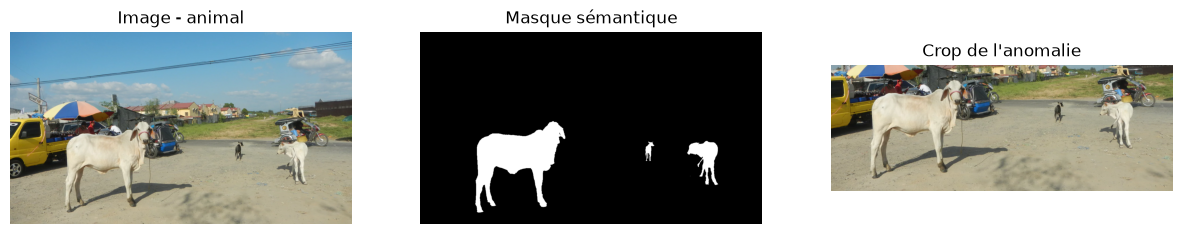

In [6]:
example = df.iloc[0]
image_path = FRAME_DIR / f"{example['name']}.webp"
mask_path = FRAME_DIR / f"{example['name']}.labels" / "labels_semantic.png"
image = plt.imread(image_path)
mask = plt.imread(mask_path)
crop = anomaly_crop(image_path, mask_path)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(image); axes[0].set_title(f"Image - {example['bo2_class']}")
axes[1].imshow(mask, cmap="gray"); axes[1].set_title("Masque sémantique")
axes[2].imshow(crop); axes[2].set_title("Crop de l'anomalie")
for axis in axes:
    axis.axis("off")
plt.show()

## 3. Construire les jeux de données

Le découpage déjÃ  présent dans `split.csv` est conservé: 36 images pour l'entrainement, 12 pour la validation et 12 pour le test. Les augmentations sont appliquées uniquement Ã  l'entrainement.

In [7]:
train_set = AnomalyDataset(FRAME_DIR, SPLIT_CSV, "train", training=True)
val_set = AnomalyDataset(FRAME_DIR, SPLIT_CSV, "val", training=False)
test_set = AnomalyDataset(FRAME_DIR, SPLIT_CSV, "test", training=False)
train_loader = make_loader(train_set, batch_size=8, training=True)
val_loader = make_loader(val_set, batch_size=8, training=False)
test_loader = make_loader(test_set, batch_size=8, training=False)
print(f"Train: {len(train_set)} | Validation: {len(val_set)} | Test: {len(test_set)}")
print("Labels train:", pd.Series(train_set.labels).map(dict(enumerate(CLASSES))).value_counts().to_dict())

Train: 36 | Validation: 12 | Test: 12
Labels train: {'animal': 19, 'obstacle': 11, 'cone': 5, 'vehicle': 1}


## 4. Choisir le modéle

Le modéle principal est ResNet18 avec des poids ImageNet. Le transfert d'apprentissage est important ici car le dataset est trés petit.

Le CNN from scratch est un baseline pédagogique. Il permet de mesurer le gain apporté par les poids pré-entrainés.

In [8]:
MODEL_NAME = "resnet18"  # changer en "scratch" pour le modéle from scratch
USE_PRETRAINED = MODEL_NAME == "resnet18"
model = build_model(MODEL_NAME, pretrained=USE_PRETRAINED).to(DEVICE)
parameter_count = sum(parameter.numel() for parameter in model.parameters())
print("Modéle :", MODEL_NAME)
print("Paramétres :", f"{parameter_count:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\ASUS/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:03<00:00, 12.4MB/s]

Modéle : resnet18
Paramétres : 11,178,564


## 5. Entrainer avec sélection par macro-F1

La macro-F1 donne le mÃªme poids Ã  chaque classe. C'est important pour BO2, car la classe `vehicle` est trés minoritaire. Le sampler équilibré est utilisé uniquement pour les mini-lots d'entrainement.

Le meilleur état est sélectionné sur la validation, puis évalué une seule fois sur le test.

In [9]:
from copy import deepcopy
from sklearn.metrics import f1_score
from torch import nn

EPOCHS = 20
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
best_state = None
best_val_f1 = -1.0

for epoch in range(1, EPOCHS + 1):
    train_loss, _, _ = run_epoch(model, train_loader, criterion, DEVICE, optimizer)
    with torch.no_grad():
        val_loss, val_targets, val_predictions = run_epoch(model, val_loader, criterion, DEVICE)
    val_f1 = f1_score(val_targets, val_predictions, labels=list(range(len(CLASSES))), average="macro", zero_division=0)
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = deepcopy(model.state_dict())
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss={train_loss:.4f} | val loss={val_loss:.4f} | val macro-F1={val_f1:.3f}")

if best_state is None:
    raise RuntimeError("Aucun état de modéle n'a été sauvegardé.")
model.load_state_dict(best_state)
print("Meilleur macro-F1 validation :", round(best_val_f1, 3))

Epoch 01/20 | train loss=1.0668 | val loss=1.0076 | val macro-F1=0.375
Epoch 02/20 | train loss=0.3529 | val loss=0.7416 | val macro-F1=0.681
Epoch 03/20 | train loss=0.1542 | val loss=0.6858 | val macro-F1=0.679
Epoch 04/20 | train loss=0.1406 | val loss=0.6752 | val macro-F1=0.679
Epoch 05/20 | train loss=0.0438 | val loss=0.6394 | val macro-F1=0.679
Epoch 06/20 | train loss=0.0486 | val loss=0.5031 | val macro-F1=0.731
Epoch 07/20 | train loss=0.0225 | val loss=0.4590 | val macro-F1=0.731
Epoch 08/20 | train loss=0.1328 | val loss=0.4650 | val macro-F1=0.731
Epoch 09/20 | train loss=0.1009 | val loss=0.4458 | val macro-F1=0.731
Epoch 10/20 | train loss=0.0639 | val loss=0.4665 | val macro-F1=0.731
Epoch 11/20 | train loss=0.0169 | val loss=0.5381 | val macro-F1=0.681
Epoch 12/20 | train loss=0.0862 | val loss=0.5930 | val macro-F1=0.681
Epoch 13/20 | train loss=0.0231 | val loss=0.5952 | val macro-F1=0.681
Epoch 14/20 | train loss=0.0226 | val loss=0.6042 | val macro-F1=0.681
Epoch 

## 6. Ã‰valuer BO2 sur le test

On affiche le F1-score de chaque classe, la macro-F1, la précision, le rappel et la matrice de confusion. Avec seulement trois images `vehicle` dans tout le dataset, le résultat de cette classe doit Ãªtre interprété avec prudence.

In [10]:
with torch.no_grad():
    test_loss, test_targets, test_predictions = run_epoch(model, test_loader, criterion, DEVICE)
print_metrics("Résultats BO2 sur le test", test_targets, test_predictions)


Résultats BO2 sur le test | macro-F1: 0.617
              precision    recall  f1-score   support

      animal      1.000     1.000     1.000         6
    obstacle      1.000     0.667     0.800         3
        cone      0.500     1.000     0.667         2
     vehicle      0.000     0.000     0.000         1

    accuracy                          0.833        12
   macro avg      0.625     0.667     0.617        12
weighted avg      0.833     0.833     0.811        12

Confusion matrix (rows=true, columns=predicted):
          animal  obstacle  cone  vehicle
animal         6         0     0        0
obstacle       0         2     1        0
cone           0         0     2        0
vehicle        0         0     1        0


## 7. Sauvegarder le modéle

Le checkpoint contient les poids, l'ordre des classes et la graine. Il pourra Ãªtre rechargé pour une démonstration ou intégré aprés le modéle U-Net.

In [11]:
output_dir = ROOT / "outputs_bo2"
output_dir.mkdir(exist_ok=True)
checkpoint_path = output_dir / f"bo2_{MODEL_NAME}_best.pt"
torch.save({"state_dict": model.state_dict(), "classes": CLASSES, "seed": SEED}, checkpoint_path)
print("Checkpoint sauvegardé :", checkpoint_path)

Checkpoint sauvegardé : c:\Users\ASUS\Pictures\RoadAnomaly\RoadAnomaly\outputs_bo2\bo2_resnet18_best.pt


## 8. Tester une image uploadée sans utiliser son nom

Cette étape reproduit le cas réel. Le nom du fichier uploadé n'est pas lu et aucune annotation n'est utilisée. Le U-Net prédit d'abord le masque de l'anomalie; le classifieur reçoit ensuite uniquement le crop de l'image prédit par ce masque.

Il faut avoir exécuté le notebook U-Net et disposer de `outputs_unet_resnet34_pretrained/unet_resnet34_pretrained_best.pt`.

In [12]:
UNET_CHECKPOINT = ROOT / "outputs_unet_resnet34_pretrained" / "unet_resnet34_pretrained_best.pt"
unet = load_unet(UNET_CHECKPOINT, DEVICE)
classifier = build_model(MODEL_NAME, pretrained=False).to(DEVICE)
classifier.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE)["state_dict"])
classifier.eval()
print("U-Net chargé :", UNET_CHECKPOINT)
print("Classifieur chargé :", checkpoint_path)

U-Net chargé : c:\Users\ASUS\Pictures\RoadAnomaly\RoadAnomaly\outputs_unet_resnet34_pretrained\unet_resnet34_pretrained_best.pt
Classifieur chargé : c:\Users\ASUS\Pictures\RoadAnomaly\RoadAnomaly\outputs_bo2\bo2_resnet18_best.pt


Remplacez `UPLOAD_PATH` par le chemin d'une image quelconque. Le fichier peut avoir n'importe quel nom: le modèle ne l'utilise pas pour prédire.

In [13]:
UPLOAD_PATH = Path(r"C:\Users\ASUS\Pictures\RoadAnomaly\RoadAnomaly\test\animals03_Zebras_in_the_road.webp")
predicted_class, confidence = classify_image(UPLOAD_PATH, classifier, unet, DEVICE)
print(f"Classe prédite : {predicted_class}")
print(f"Confiance : {confidence:.1%}")

Classe prédite : animal
Confiance : 99.8%


## Interprétation et limites

- Le F1 par classe est le critére principal de BO2.
- Le score `vehicle` est peu fiable avec une seule image de test.
- Les masques annotés servent uniquement à préparer les crops d'entraînement et à mesurer la classification. L'inférence uploadée utilise le masque prédit par le U-Net.
- Pour une conclusion robuste, ajouter des images de véhicules et répéter l'évaluation avec une validation croisée stratifiée.